In [1]:
# PyTorch: tensores, redes neuronales, funciones y optimizadores
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split, Subset

# Visión artificial y carga de CIFAR-10
import torchvision
import torchvision.transforms as transforms

# Cálculo numérico, gráficas y utilidades
import numpy as np
import matplotlib.pyplot as plt
import random
import time

# Semillas para que los experimentos sean reproducibles
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Selección automática de GPU si está disponible; si no, CPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Dispositivo:", DEVICE)   

PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
Dispositivo: cuda


In [2]:
def accuracy_from_logits(logits, labels):
    pred = logits.argmax(dim=1)
    return (pred == labels).sum().item(), labels.size(0)

def run_epoch(model, loader, criterion, optimizer=None, log_batches=False):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_correct = 0
    total_items = 0
    batch_losses = []

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for batch_idx, (inputs, labels) in enumerate(loader):
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

            if training:
                optimizer.zero_grad()

            logits = model(inputs)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            correct, count = accuracy_from_logits(logits, labels)
            total_correct += correct
            total_items += count
            batch_losses.append(loss.item())

    return total_loss / total_items, 100 * total_correct / total_items, batch_losses


def show_image_tensor(img, ax=None, title=None):
    img = img.detach().cpu() * 0.5 + 0.5  # desnormalizar
    img = img.clamp(0, 1).permute(1, 2, 0).numpy()
    if ax is None:
        plt.figure(figsize=(3, 3))
        plt.imshow(img)
        plt.axis("off")
        if title:
            plt.title(title)
        plt.show()
    else:
        ax.imshow(img)
        ax.axis("off")
        if title:
            ax.set_title(title)

def train_model(model, train_loader, val_loader, epochs=4, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [], "train_acc": [],
        "val_loss": [], "val_acc": [],
        "batch_loss": []
    }

    for epoch in range(epochs):
        start = time.time()
        train_loss, train_acc, batch_losses = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_acc, _ = run_epoch(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["batch_loss"].append(batch_losses)

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"train loss {train_loss:.3f} acc {train_acc:5.1f}% | "
            f"val loss {val_loss:.3f} acc {val_acc:5.1f}% | "
            f"{time.time()-start:.1f}s"
        )
    return history

In [3]:
from torchvision.datasets import ImageFolder
from torch.utils.data import TensorDataset
from collections import Counter

DATA_DIR = "archive/raw-img"
IMG_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 1e-3

NOMBRES = {"cane": "perro", "cavallo": "caballo", "elefante": "elefante",
           "farfalla": "mariposa", "gallina": "gallina", "gatto": "gato",
           "mucca": "vaca", "pecora": "oveja", "ragno": "araña", "scoiattolo": "ardilla"}

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

dataset = ImageFolder(DATA_DIR, transform=transform)
classes = [NOMBRES[c] for c in dataset.classes]
print("Clases:", classes)
print("Imágenes por clase:", {classes[k]: v for k, v in sorted(Counter(dataset.targets).items())})

Clases: ['perro', 'caballo', 'elefante', 'mariposa', 'gallina', 'gato', 'vaca', 'oveja', 'araña', 'ardilla']
Imágenes por clase: {'perro': 4863, 'caballo': 2623, 'elefante': 1446, 'mariposa': 2112, 'gallina': 3098, 'gato': 1668, 'vaca': 1866, 'oveja': 1820, 'araña': 4821, 'ardilla': 1862}


In [4]:
inicio = time.time()
imagenes = torch.empty(len(dataset), 3, IMG_SIZE, IMG_SIZE)
for i, (img, _) in enumerate(dataset):
    imagenes[i] = img
etiquetas = torch.tensor(dataset.targets)
datos = TensorDataset(imagenes, etiquetas)
print(f"{len(datos)} imágenes {tuple(imagenes.shape)} cargadas en {time.time() - inicio:.0f} s")

26179 imágenes (26179, 3, 64, 64) cargadas en 33 s


In [5]:
n_train = int(0.70 * len(datos))
n_val = int(0.15 * len(datos))
n_test = len(datos) - n_train - n_val

g = torch.Generator().manual_seed(SEED)
train_subset, val_subset, test_subset = random_split(datos, [n_train, n_val, n_test], generator=g)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE)
print("train / val / test:", n_train, n_val, n_test)

train / val / test: 18325 3926 3928


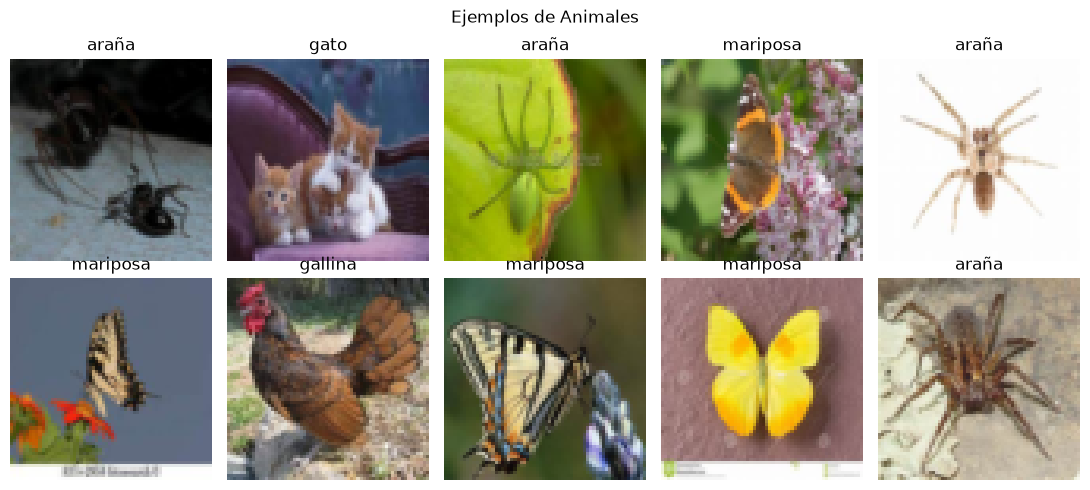

Forma del batch: torch.Size([32, 3, 64, 64])
Forma de las etiquetas: torch.Size([32])


In [9]:


images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    show_image_tensor(images[i], ax, classes[labels[i]])
plt.suptitle("Ejemplos de Animales")
plt.tight_layout()
plt.show()

print("Forma del batch:", images.shape)
print("Forma de las etiquetas:", labels.shape)

In [10]:
class MiCNN(nn.Module):
    def __init__(self, num_classes, img_size=IMG_SIZE, dropout_p=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2)
        )
        lado = img_size // 4
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * lado * lado, 128),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = MiCNN(num_classes=len(classes)).to(DEVICE)
history = train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE)

Epoch 01/15 | train loss 1.841 acc  34.9% | val loss 1.540 acc  46.8% | 2.1s
Epoch 02/15 | train loss 1.505 acc  47.7% | val loss 1.361 acc  52.8% | 1.9s
Epoch 03/15 | train loss 1.335 acc  53.7% | val loss 1.306 acc  54.7% | 1.9s
Epoch 04/15 | train loss 1.210 acc  58.4% | val loss 1.224 acc  58.3% | 1.9s
Epoch 05/15 | train loss 1.092 acc  62.4% | val loss 1.222 acc  58.6% | 1.9s
Epoch 06/15 | train loss 0.986 acc  66.1% | val loss 1.190 acc  59.7% | 1.8s
Epoch 07/15 | train loss 0.869 acc  70.1% | val loss 1.193 acc  59.9% | 1.7s
Epoch 08/15 | train loss 0.763 acc  73.5% | val loss 1.268 acc  59.5% | 1.6s
Epoch 09/15 | train loss 0.671 acc  76.3% | val loss 1.312 acc  59.5% | 1.7s
Epoch 10/15 | train loss 0.591 acc  79.1% | val loss 1.347 acc  59.5% | 1.7s
Epoch 11/15 | train loss 0.509 acc  82.1% | val loss 1.379 acc  59.7% | 1.7s
Epoch 12/15 | train loss 0.451 acc  83.8% | val loss 1.548 acc  60.0% | 1.7s
Epoch 13/15 | train loss 0.406 acc  85.5% | val loss 1.516 acc  59.7% | 1.7s

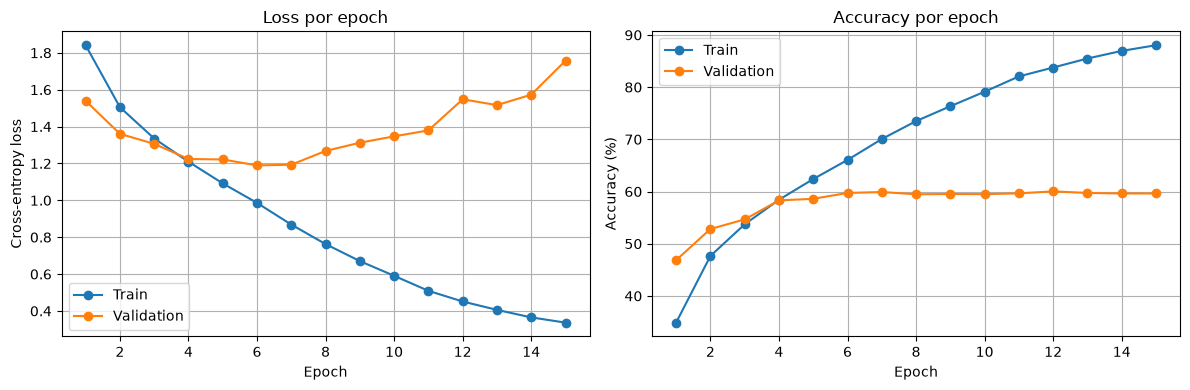

In [11]:
epochs_axis = np.arange(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_axis, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs_axis, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss por epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].grid(True); axes[0].legend()

axes[1].plot(epochs_axis, history["train_acc"], marker="o", label="Train")
axes[1].plot(epochs_axis, history["val_acc"], marker="o", label="Validation")
axes[1].set_title("Accuracy por epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True); axes[1].legend()
plt.tight_layout()
plt.show()

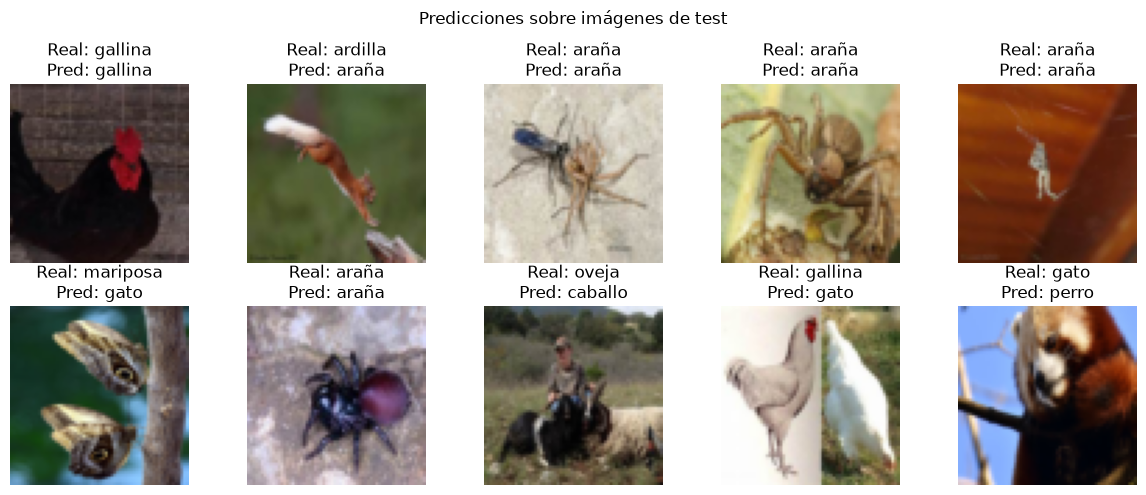

Test loss: 1.684
Test accuracy: 61.43%


In [13]:
model.eval()
test_images, test_labels = next(iter(test_loader))
with torch.no_grad():
    test_logits = model(test_images.to(DEVICE))
    test_preds = test_logits.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ok = test_preds[i].item() == test_labels[i].item()
    title = f"Real: {classes[test_labels[i]]}\nPred: {classes[test_preds[i]]}"
    show_image_tensor(test_images[i], ax, title)
plt.suptitle("Predicciones sobre imágenes de test")
plt.tight_layout()
plt.show()

test_loss, test_acc, _ = run_epoch(model, test_loader, nn.CrossEntropyLoss())
print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_acc:.2f}%")